# Phase 1: LLaDA-8B-Instruct on a MacBook

This notebook walks through steps 1.0-1.4 of `docs/PHASE1_LLADA_ON_MAC.md` using only the **committed results** in `results/phase1/`. It never loads the model, so it runs in seconds. To regenerate the results, use `scripts/run_phase1.sh` (about 5 h on a 24 GB M-series Mac), then `python -m src.phase1.report_grid` and `python -m src.phase1.calibration`. Per-step details (command, config, hardware, seed, wall-clock) are in `experiments/1.x/README.md`.

All sample sizes are small (n = 5-12 per task) because of compute, so read every number together with its interval.

In [1]:
import os, json, csv
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display
REPO = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
R = REPO / 'results/phase1'
pd.set_option('display.precision', 3); pd.set_option('display.max_colwidth', 60)

## 1.0 Setup, loading and speed

LLaDA-8B-Instruct loads in bf16 straight onto MPS (16 GB) and answers the GSM8K smoke question correctly. The key number for planning is **about 1 s per denoising step**: a 64-token answer at 64 steps takes about a minute. This machine was shared with a Docker VM and the phase-2 job, and the first attempt thrashed swap. Both are recorded below.

In [2]:
display(Markdown((R / 'env_and_speed.md').read_text()))

# 1.0 Environment and speed (LLaDA-8B-Instruct on MPS)

- Model: `GSAI-ML/LLaDA-8B-Instruct` @ `08b83a6feb34df1a6011b80c3c00c7563e963b07`, dtype bfloat16, device `mps`
- Machine: Apple M5, 25.8 GB unified memory; macOS-27.0.1-arm64-arm-64bit
- python 3.12.13, torch 2.15.0, transformers 4.38.2
- `iogpu.wired_limit_mb` = 0 (macOS default, not changed). MPS recommended max working set: 19.1 GB
- Concurrent load: a Docker Desktop VM (~8.2 GB resident, user's long-running containers, left untouched), VS Code, and intermittently another job of this repo (phase-2 toy model training, ~1M params). With the 16 GB model resident, the system sits at ~22-24 GB used of 25.8 GB and ~15 GB of swap is in use, so timings are those of a memory-tight, shared machine.
- Failed first attempt (recorded for honesty): the first smoke run loaded with `.to("mps")` after a CPU load; a leftover killed process still held 16 GB and the next run thrashed swap (first forward pass 142 s). After that process exited and loading switched to `device_map={"": "mps"}` (no CPU copy), loading takes ~9 s and memory is stable.
- Load time: 8.9 s (weights already in local HF cache)

## Memory (GB)

| when | process RSS | MPS driver allocated | MPS current allocated | system used | swap used |
|---|---|---|---|---|---|
| before load | 0.2 | 0.0 | 0.0 | 7.4 | 15.5 |
| after load | 0.2 | 17.1 | 16.0 | 22.4 | 19.2 |
| after smoke gen | 0.2 | 17.1 | 16.0 | 24.4 | 15.2 |
| after timing | 0.0 | 17.1 | 16.0 | 24.6 | 15.1 |

## Smoke test

GSM8K test[0], d1 zero-shot prompt, `gen_length=128, steps=64, block_length=32`, greedy, `confidence` (= LLaDA `low_confidence`).
- prompt tokens: 148; forward passes: 64
- total: 56.1 s; **0.88 s per denoising step**
- reference answer 18.0; extracted 18.0; correct: True

```
Janet's ducks lay 16 eggs per day. She eats 3 eggs for breakfast and bakes 4 eggs for her friends, which means she uses a total of \(3 + 4 = 7\) eggs per day. Therefore, she has \(16 - 7 = 9\) eggs left to sell. She sells each egg for $2, so she makes \(9 \times 2 = 18\) dollars per day.
</reasoning>
<answer>
\boxed{18}
</answer>
```

## Seconds per denoising step vs sequence length (8 steps each, batch 1)

| task prompt | prompt tokens | gen_length | total seq | s/step |
|---|---|---|---|---|
| sudoku | 220 | 64 | 284 | 1.06 |
| sudoku | 220 | 128 | 348 | 1.18 |
| countdown | 156 | 64 | 220 | 0.77 |
| countdown | 156 | 128 | 284 | 1.30 |
| gsm8k | 148 | 128 | 276 | 1.33 |
| gsm8k | 148 | 256 | 404 | 1.74 |

Notes:
- The timing rows include the MPS warm-up for each new sequence length (the first 1-3 forward passes at a new shape are several times slower), so they overstate the steady-state cost. A separate measurement on the Sudoku prompt (284 tokens) gave 1.1-1.4 s per forward pass warm; a short Countdown grid smoke run gave ~0.9 s/step. A forward pass at 256 random tokens measured 0.38 s once while the machine was otherwise idle, so contention/memory pressure roughly doubles to triples the cost here.
- MPS is not fully deterministic; numbers are single measurements, not averages over runs.

## Sizing decision for 1.2
Using ~1.3 s/step (Sudoku/Countdown, gen_length 64) and ~1.4 s/step (GSM8K, gen_length 128): one example over the full grid (4 strategies x steps {gen/4, gen/2, gen}) costs 7 x gen_length forward passes = 448 passes (~10 min) for Sudoku/Countdown and 896 passes (~21 min) for GSM8K at gen_length 128. GSM8K at gen_length 256 would be ~50 min per example. To keep total Phase 1 compute to ~6 h we run 12 Sudoku, 12 Countdown and 5 GSM8K examples, GSM8K at gen_length 128 (see experiments/1.2/README.md).


## 1.1 In which order does LLaDA unmask?

For 3 prompts per task we generated 128 tokens in 64 steps (2 tokens per step, blocks of 32), once with LLaDA's default `low_confidence` remasking and once with random order. In each heatmap, the top panel shows *when* each answer position was committed and the bottom panel its confidence at that moment. The GIFs in `results/phase1/unmasking/` show the decoded text after every step.

,task,id,remasking,steps,gen_length,score,correct,mean_conf,wall_s
0,sudoku,sudoku-320,low_confidence,64,128,0.125,0,0.776,101.2
1,sudoku,sudoku-320,random,64,128,0.250,0,0.679,87.8
2,sudoku,sudoku-275,low_confidence,64,128,0.250,0,0.764,87.6
3,sudoku,sudoku-275,random,64,128,0.375,0,0.702,87.2
4,sudoku,sudoku-14,low_confidence,64,128,0.000,0,0.755,86.6
5,sudoku,sudoku-14,random,64,128,0.000,0,0.691,87.9
6,countdown,countdown-26,low_confidence,64,128,1.000,1,0.766,82.6
7,countdown,countdown-26,random,64,128,0.000,0,0.790,81.6
8,countdown,countdown-212,low_confidence,64,128,0.000,0,0.764,82.7
9,countdown,countdown-212,random,64,128,0.000,0,0.734,82.6


**sudoku-320**  (GIFs: `results/phase1/unmasking/sudoku-320_low_confidence.gif`, `..._random.gif`)

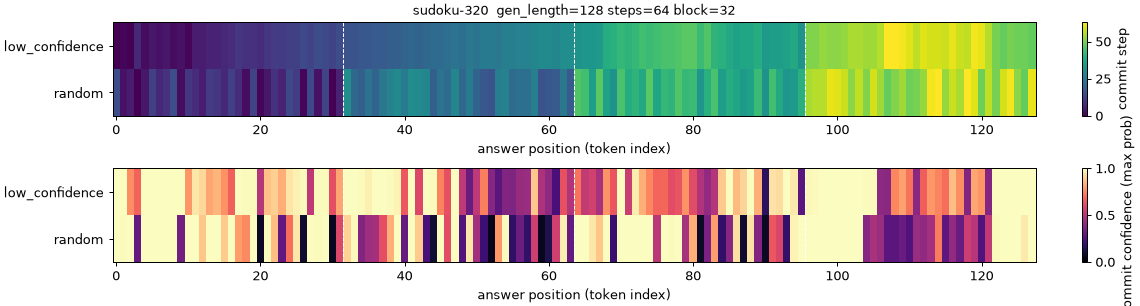

**countdown-26**  (GIFs: `results/phase1/unmasking/countdown-26_low_confidence.gif`, `..._random.gif`)

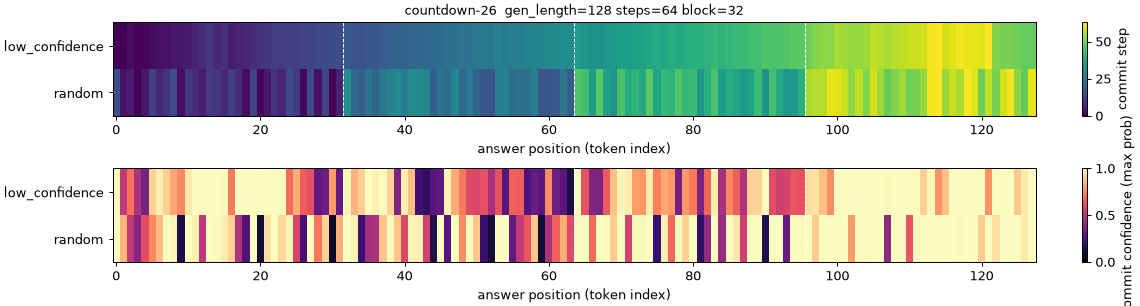

**gsm8k-416**  (GIFs: `results/phase1/unmasking/gsm8k-416_low_confidence.gif`, `..._random.gif`)

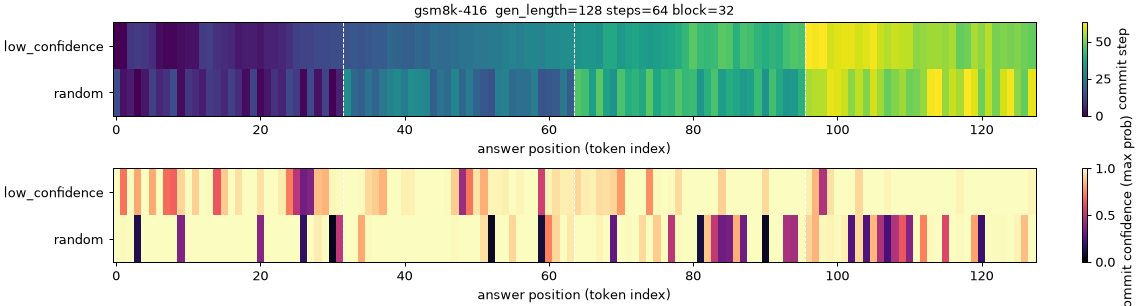

In [3]:
runs = pd.read_csv(R / 'unmasking/runs.csv')
display(runs[['task','id','remasking','steps','gen_length','score','correct','mean_conf','wall_s']])
for pid in runs['id'].unique()[::3]:   # one prompt per task, to keep the notebook small
    display(Markdown(f'**{pid}**  (GIFs: `results/phase1/unmasking/{pid}_low_confidence.gif`, `..._random.gif`)'))
    display(Image(filename=str(R / f'unmasking/{pid}_heatmap.png'), width=760))

In [4]:
# Quantify the left-to-right tendency inside blocks: Spearman correlation between position and commit step
import numpy as np
from scipy.stats import spearmanr
rows = []
for f in sorted((R / 'unmasking').glob('*_*.json')):
    d = json.load(open(f)); cs = np.array(d['commit_step'])
    name = f.stem
    strat = 'low_confidence' if name.endswith('low_confidence') else 'random'
    pid = name.replace('_low_confidence', '').replace('_random', '')
    rhos = [spearmanr(np.arange(32), cs[b:b+32]).correlation for b in range(0, len(cs), 32)]
    rows.append({'id': pid, 'remasking': strat, 'mean within-block rho(position, commit step)': np.nanmean(rhos)})
df = pd.DataFrame(rows); display(df.drop(columns='id').groupby('remasking').agg(['mean', 'min', 'max']))

mean within-block rho(position, commit step)              
                                                       mean    min    max
remasking                                                                
low_confidence                                        0.641  0.372  0.856
random                                               -0.182 -0.182 -0.182

## 1.2 Strategies vs step budget

Four scoring rules decide which masked positions to commit at each step:
- `random`;
- `confidence` (max probability, i.e. LLaDA's `low_confidence`);
- `margin` (top-1 minus top-2 probability);
- `entropy` (lowest entropy first).

Each rule was run at 0.25x, 0.5x and 1x steps per token, on the same examples (paired design). Sample sizes: n = 12 Sudoku, 12 Countdown, 5 GSM8K. The spec asked for 100/100/50, which would have taken days at about 1 s per step (see `experiments/1.2/README.md`). Intervals are 95% bootstraps over examples.

In [5]:
s = pd.read_csv(R / 'strategies.csv'); display(s)

,task,strategy,steps,gen_length,n,accuracy,acc_lo,acc_hi,solved,solved_lo,solved_hi,mean_wall_s,forward_passes
0,sudoku,confidence,16,64,12,0.156,0.052,0.271,0.000,0.000,0.000,20.363,16
1,sudoku,confidence,32,64,12,0.073,0.010,0.157,0.000,0.000,0.000,40.755,32
2,sudoku,confidence,64,64,12,0.052,0.000,0.115,0.000,0.000,0.000,81.298,64
3,sudoku,entropy,16,64,12,0.073,0.021,0.125,0.000,0.000,0.000,20.370,16
4,sudoku,entropy,32,64,12,0.083,0.010,0.177,0.000,0.000,0.000,40.588,32
5,sudoku,entropy,64,64,12,0.021,0.000,0.052,0.000,0.000,0.000,81.262,64
6,sudoku,margin,16,64,12,0.115,0.062,0.167,0.000,0.000,0.000,20.606,16
7,sudoku,margin,32,64,12,0.052,0.000,0.125,0.000,0.000,0.000,41.184,32
8,sudoku,margin,64,64,12,0.062,0.021,0.115,0.000,0.000,0.000,82.257,64
9,sudoku,random,16,64,12,0.135,0.062,0.208,0.000,0.000,0.000,20.884,16


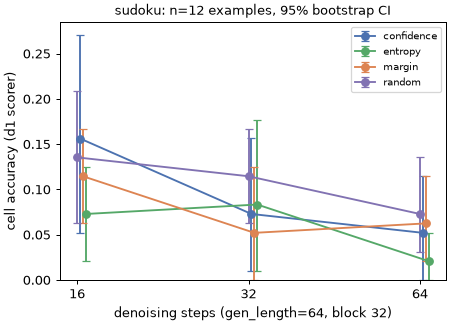

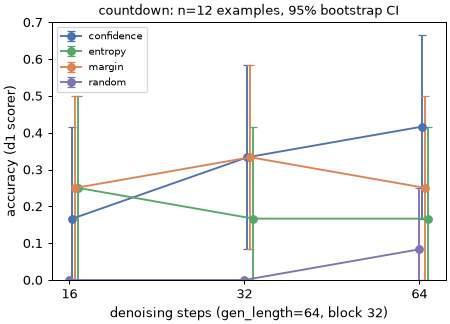

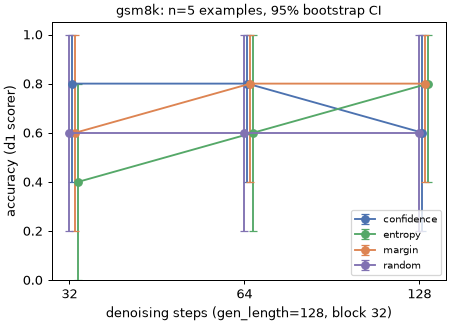

In [6]:
for t in ['sudoku', 'countdown', 'gsm8k']:
    p = R / f'strategies_{t}.png'
    if p.exists(): display(Image(filename=str(p), width=480))

In [7]:
# paired over examples, averaged over the 3 step budgets: confidence minus each other strategy
display(pd.read_csv(R / 'strategies_paired.csv'))

,task,comparison,n_examples,mean_diff,lo,hi
0,sudoku,confidence - entropy,12,0.035,-0.035,0.132
1,sudoku,confidence - margin,12,0.017,-0.031,0.083
2,sudoku,confidence - random,12,-0.014,-0.073,0.069
3,countdown,confidence - entropy,12,0.111,-0.056,0.250
4,countdown,confidence - margin,12,0.028,-0.222,0.223
5,countdown,confidence - random,12,0.278,0.111,0.444
6,gsm8k,confidence - entropy,5,0.133,0.000,0.267
7,gsm8k,confidence - margin,5,0.000,0.000,0.000
8,gsm8k,confidence - random,5,0.133,0.000,0.400


**Reading the grid.**
- **Countdown** is the only task with a clear signal: confidence order beats random by +0.28 [0.11, 0.44] (paired, averaged over budgets). Margin and entropy lie between them, and their intervals overlap confidence's.
- **GSM8K** at n = 5 cannot separate any strategies.
- **Sudoku** is at the floor (0 full solves out of 144). The model mostly copies the puzzle into the answer, so the Sudoku comparison says nothing about the strategies.
- **Fewer steps were not detectably worse**, while wall time scales linearly with steps. That is a hint, not a result, at this n.

## 1.3 Does commit confidence predict errors?

Using the `confidence` runs at the full budget, we treat the commit confidence of the answer tokens (their mean or minimum) as a predicted probability of being correct. We report reliability diagrams, ECE and AUROC. For Sudoku we also do this per empty cell. Finally, we check whether tokens committed early are right more often than those committed late.

In [8]:
display(pd.read_csv(R / 'calibration/metrics.csv'))
p = R / 'calibration/early_vs_late.csv'
if p.exists(): display(pd.read_csv(p))
display(pd.read_csv(R / 'calibration/sudoku_cells_by_digit.csv'))

,task,level,confidence,n,accuracy,mean_confidence,ece,ece_lo,ece_hi,auroc,auroc_lo,auroc_hi
0,sudoku,answer,mean commit conf (content tokens),12,0.000,0.821,0.821,0.809,0.832,NaN,NaN,NaN
1,sudoku,answer,min commit conf (content tokens),12,0.000,0.210,0.210,0.185,0.235,NaN,NaN,NaN
2,countdown,answer,mean commit conf (content tokens),12,0.417,0.871,0.454,0.203,0.706,0.629,0.222,0.963
3,countdown,answer,min commit conf (content tokens),12,0.417,0.298,0.178,0.054,0.450,0.571,0.188,0.938
4,gsm8k,answer,mean commit conf (content tokens),5,0.600,0.946,0.346,0.040,0.737,1.000,1.000,1.000
5,gsm8k,answer,min commit conf (content tokens),5,0.600,0.434,0.166,0.033,0.577,0.500,0.000,1.000
6,sudoku,token (empty cell),commit conf of the cell's token,96,0.052,0.715,0.663,0.602,0.725,0.103,0.043,0.166


,task,unit,commit_order,n,accuracy,lo,hi
0,sudoku,empty cell,first third,36,0.056,0.000,0.139
1,sudoku,empty cell,middle third,24,0.083,0.000,0.208
2,sudoku,empty cell,last third,36,0.028,0.000,0.083
3,sudoku,answer,answer span committed early (<= median),7,0.000,0.000,0.000
4,sudoku,answer,answer span committed late (> median),5,0.000,0.000,0.000
5,countdown,answer,answer span committed early (<= median),6,0.500,0.167,0.833
6,countdown,answer,answer span committed late (> median),6,0.333,0.000,0.667
7,gsm8k,answer,answer span committed early (<= median),3,0.667,0.000,1.000
8,gsm8k,answer,answer span committed late (> median),2,0.500,0.000,1.000


,digit_written,n_cells,mean_commit_conf,cell_accuracy
0,0,71,0.751,0.000
1,1,9,0.601,0.222
2,2,7,0.710,0.143
3,4,6,0.558,0.000
4,3,3,0.545,0.667


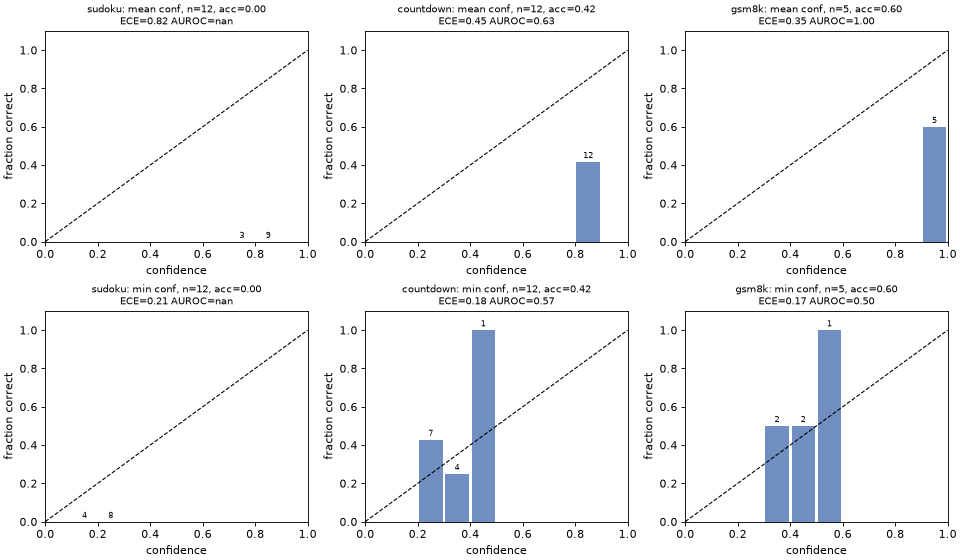

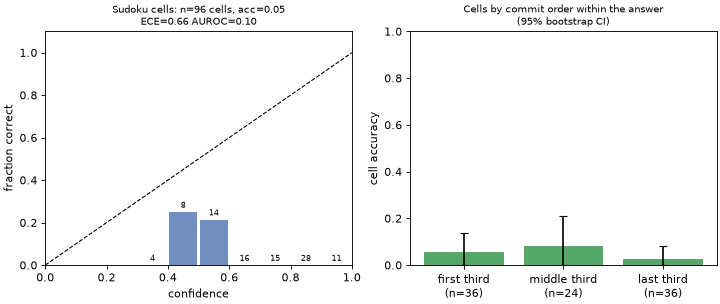

In [9]:
for f in ['reliability_answer_level.png', 'sudoku_token_level.png']:
    p = R / 'calibration' / f
    if p.exists(): display(Image(filename=str(p), width=720))

**Reading the calibration.**
- **Overconfident.** Mean commit confidence is 0.87-0.95, while accuracy is 0.42-0.60, and its AUROC on Countdown is not distinguishable from 0.5.
- **Sudoku cells are anti-calibrated** (AUROC 0.10). The digit table shows why: 71 of 96 empty cells received the puzzle's `0`, copied with high confidence, and all of them are wrong. High confidence here marks *easy-to-copy* tokens, not correct ones.
- **Early vs late commit order** shows no clear difference at this n.

## 1.4 Summary

The written summary (`results/phase1/SUMMARY.md`) is reproduced below. It covers setup, headline numbers with intervals, limitations and open questions for phase 2.

In [10]:
# image links in SUMMARY.md are relative to results/phase1/; rewrite them for the notebook folder
display(Markdown((R / 'SUMMARY.md').read_text().replace('](', '](../results/phase1/')))

# Phase 1 summary: LLaDA-8B-Instruct on a MacBook

## Setup
- LLaDA-8B-Instruct (revision `08b83a6f`), bf16 on Apple MPS (M5, 24 GB), torch 2.15.0, transformers 4.38.2.
- Sampler: LLaDA's `generate.py` (commit `9182493`) with instrumentation and four unmasking strategies.
- Tasks: d1's zero-shot prompts and scorers (commit `faf85d6`) for Sudoku 4x4, Countdown-3 and GSM8K.
- Decoding: block length 32, temperature 0, no CFG; seed 42 throughout.
- The machine was shared with a Docker VM (~8 GB) and the phase-2 training job, so speeds are under contention.
- Phase 1 compute was about 5.0 h:
  - 1.0 smoke: 3 min;
  - 1.1: 25 min;
  - 1.2 grid: 4 h 34 min;
  - 1.3: seconds;
  - plus a ~75 min model download and one failed first load (swap thrashing; see `env_and_speed.md`).

## Speed (1.0)
16 GB on MPS. **About 0.9 s per denoising step** (0.38 s per forward pass when the machine was idle, 0.8-1.4 s under contention), so a 64-token answer at 64 steps takes about 1 min. Cost is linear in steps, and every strategy costs the same per step.

## Unmasking order (1.1), 9 prompts, gen 128, 64 steps
![heatmap](../results/phase1/unmasking/gsm8k-416_heatmap.png)

With `low_confidence`, LLaDA fills each 32-token block mostly left to right: within-block Spearman rho(position, commit step) = **0.64** on average (range 0.37-0.86). With random order, rho is -0.18, as expected for an arbitrary permutation. Under random order the intermediate text is visibly incoherent (GIFs in `unmasking/`).

## Strategies vs steps (1.2); 95% bootstrap CIs over examples
Countdown (n = 12):

![countdown](../results/phase1/strategies_countdown.png)

| task (n) | confidence @1x | margin @1x | entropy @1x | random @1x |
|---|---|---|---|---|
| Sudoku cell acc. (12) | 0.05 [0.00, 0.11] | 0.06 [0.02, 0.11] | 0.02 [0.00, 0.05] | 0.07 [0.03, 0.14] |
| Countdown (12) | 0.42 [0.17, 0.67] | 0.25 [0.00, 0.50] | 0.17 [0.00, 0.42] | 0.08 [0.00, 0.25] |
| GSM8K, gen 128 (5) | 0.60 [0.20, 1.00] | 0.80 [0.40, 1.00] | 0.80 [0.40, 1.00] | 0.60 [0.20, 1.00] |

- The only paired difference whose interval excludes 0 is **Countdown confidence - random: +0.28 [0.11, 0.44]** (averaged over budgets; `strategies_paired.csv`). Confidence, margin and entropy cannot be told apart at this n.
- Fewer steps (0.25x, 0.5x) did not detectably hurt, and each halving of the steps halves the wall time.
- Sudoku is at the floor for every strategy: 0 full solves out of 144 generations.

## Calibration (1.3), confidence strategy, full budget
![cells](../results/phase1/calibration/sudoku_token_level.png)

- Mean commit confidence is **overconfident**: 0.87 confidence against 0.42 accuracy on Countdown, and 0.95 against 0.60 on GSM8K. ECE is 0.45 [0.20, 0.71] on Countdown, and the AUROC of 0.63 [0.22, 0.96] is not distinguishable from chance.
- **Sudoku cell confidence is anti-predictive (AUROC 0.10 [0.04, 0.17], n = 96 cells).** 71 of 96 empty cells were filled with the puzzle's `0`, copied at confidence 0.75, and all of them are wrong. Confidence measures how easy a token is to copy, not whether the cell is correct.
- Early- vs late-committed tokens: no clear difference (all intervals overlap).

## Limitations
- **Tiny samples.** n = 12/12/5 instead of the spec's 100/100/50, chosen to fit about 6 h of compute at ~1 s per step. Intervals are +/-0.2-0.4, so these are pilot numbers.
- **Shorter GSM8K answers.** GSM8K ran at gen 128 instead of 256.
- **Copy heuristic dominates Sudoku.** Sudoku accuracy is d1's cell metric at 64 tokens. The model mostly copies the puzzle, so the Sudoku strategy comparison is uninformative.
- **Platform differences.** bf16 on MPS (Gumbel noise in fp32, unused at temperature 0), a shared machine, and no exact match with the paper's or d1's evaluation settings: gen lengths, few-shot and n all differ. Numbers are not comparable to published LLaDA/d1 results.
- **One random seed per example.** Variance across seeds was not measured.

## Next questions for phase 2
- Does RL (wd1/d1-style) on a Sudoku-specialised model fix the copy-the-zeros failure, and does commit confidence become predictive after training?
- Is margin or entropy better than max-probability once a model is competent? At this n we cannot tell.
- Can a recalibrated confidence (e.g. min over the answer span, or a learned probe) be used to adapt the step budget per example, given that fewer steps cost little accuracy here?
